<div style=" background-color: RGB(0,114,200);" >
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 10 - DATA ANALYST</h2>
<h3 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Détectez des faux billets avec Python </h3>
</div>

**Contexte** :

L’Organisation nationale de lutte contre le faux-monnayage, ou ONCFM, est une organisation publique ayant pour objectif de mettre en place des méthodes d’identification des contrefaçons des billets en euros. Dans le cadre de cette lutte, nous souhaitons mettre en place un algorithme qui soit capable de différencier automatiquement les vrais des faux billets.

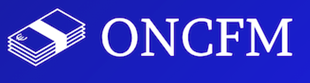

**Objectifs** : 

Lorsqu’un billet arrive, nous avons une machine qui consigne l’ensemble de ses caractéristiques géométriques. Au travers de nos années de lutte, nous avons observé des différences de dimensions entre les vrais et les faux billets. Ces différences sont difficilement notables à l’oeil nu, mais une machine devrait sans problème arriver à les différencier. Ainsi, il faudrait construire un algorithme qui, à partir des caractéristiques géométriques d’un billet, serait capable de définir si ce dernier est un vrai ou un faux billet.

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">Importation des librairies</h3>
</div>

In [1]:
# ── Librairies de base pour manipulation des données ──
import pandas as pd
import numpy as np
import warnings
import pickle
import os
from math import pi

# ── Librairies de visualisation ──
import matplotlib.pyplot as plt
import seaborn as sns

# ── Librairies pour l'analyse statistique ──
import statsmodels.api as sm
from scipy.stats import shapiro
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

# ── Librairies de machine learning ──
# Algorithmes
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression

# Préparation des données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler, StandardScaler

# Métriques d'évaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score, roc_curve, auc
)

# ── Configuration des affichages ──
warnings.filterwarnings('ignore')
plt.style.use('default')  # Style par défaut pour matplotlib

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">Chargement des fichiers</h3>
</div>

In [2]:
# Importation du fichier
chemin = r"C:\Users\CRFP4534\OneDrive - orange.com\Bureau\Formation CFA - Data Analyst\P10-Détectez des faux billets avec R ou Python\\"
df = pd.read_csv(chemin + r"Data\billets.csv", delimiter=";")

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Analyse descriptive</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 Informations de base</h3>
</div>

In [3]:
# Les 5 premières lignes
df.head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [4]:
# Caractéristiques des colonnes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
dtypes: bool(1), float64(6)
memory usage: 71.9 KB


+ Nous avons 1500 observations.
+ Seule la colonne "margin_low" contient des valeurs manquantes.

In [5]:
# Nombre de billets par catégorie "is_genuine"
print(df['is_genuine'].value_counts())

is_genuine
True     1000
False     500
Name: count, dtype: int64


+ 1500 lignes dont 1000 sont des vrais billets et 500 sont des faux billets

In [6]:
# Informations sur les colonnes numériques
df.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1500.000000,1500.000000,1500.000000,1463.000000,1500.000000,1500.00000
mean,171.958440,104.029533,103.920307,4.485967,3.151473,112.67850
std,0.305195,0.299462,0.325627,0.663813,0.231813,0.87273
min,171.040000,103.140000,102.820000,2.980000,2.270000,109.49000
25%,171.750000,103.820000,103.710000,4.015000,2.990000,112.03000
50%,171.960000,104.040000,103.920000,4.310000,3.140000,112.96000
75%,172.170000,104.230000,104.150000,4.870000,3.310000,113.34000
max,173.010000,104.880000,104.950000,6.900000,3.910000,114.44000


+ À partir de ces informations, nous pouvons conclure que les dimensions géométriques d'un vrai billet sont approximativement les suivantes :
  + diagonal :171 mm
  + height_left : 104 mm
  + height_right : 104 mm
  + margin_low :4 mm
  + margin_up : 3 mm
  + length :  113 mm

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 Distribution des données</h3>
</div>

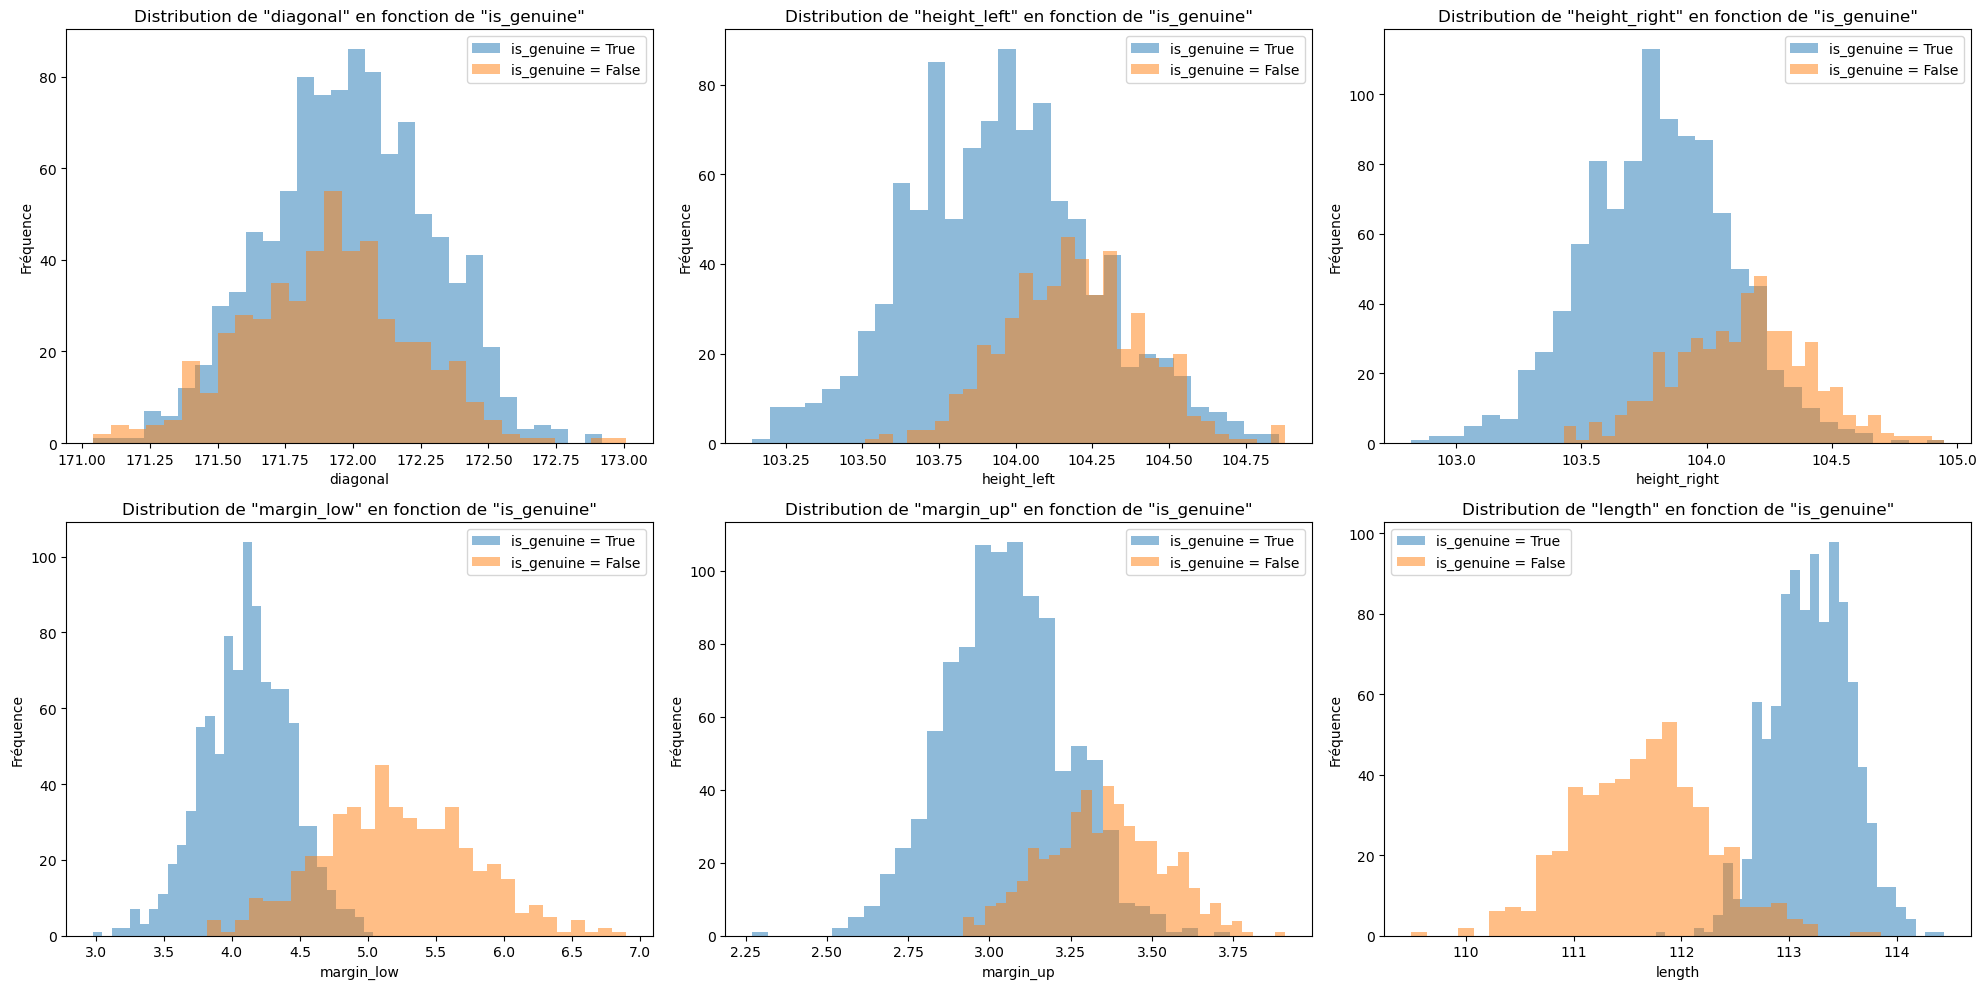

In [7]:
# Distribution de chaque colonne numérique en fonction de la colonne "is_genuine"
# Sélectionner les colonnes numériques, en excluant "is_genuine"
colonnes_num = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if "is_genuine" in colonnes_num:
    colonnes_num.remove("is_genuine")

n = len(colonnes_num)
nrows = (n + 2) // 3  # Calcul du nombre de lignes avec 3 graphiques par ligne

fig, axes = plt.subplots(nrows, 3, figsize=(20, 5 * nrows))
axes = axes.flatten() if n > 1 else [axes]

for ax, col in zip(axes, colonnes_num):
    for valeur in df["is_genuine"].unique():
        sous_ensemble = df[df["is_genuine"] == valeur]
        ax.hist(sous_ensemble[col], bins=30, alpha=0.5, label=f'is_genuine = {valeur}')
    ax.set_title(f'Distribution de "{col}" en fonction de "is_genuine"')
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")
    ax.legend()

plt.tight_layout()
plt.show()

+ À première vue, une tendance émerge entre les variables "margin_low" et "length" pour distinguer les faux billets : 
  + "margin_low" supérieur à 5
  + "length" inférieur à 112

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.3 Imputation des valeurs manquantes</h3>
</div>

In [8]:
# Régression linéaire pour prédire "margin_low" en fonction des autres variables
# Sélection des lignes sans valeurs manquantes pour l'entraînement
df_train = df[df["margin_low"].notna()]
x_train = df_train[["diagonal", "height_left", "height_right", "margin_up", "length"]]
y_train = df_train["margin_low"]

# Ajout d'une constante pour le terme d'interception
x_train_const = sm.add_constant(x_train)

# Création et entraînement du modèle OLS (Ordinary Least Squares)
modele = sm.OLS(y_train, x_train_const).fit()

# Affichage du résumé du modèle
print(modele.summary()) 

                            OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.477
Model:                            OLS   Adj. R-squared:                  0.476
Method:                 Least Squares   F-statistic:                     266.1
Date:                Fri, 01 Aug 2025   Prob (F-statistic):          2.60e-202
Time:                        11:58:50   Log-Likelihood:                -1001.3
No. Observations:                1463   AIC:                             2015.
Df Residuals:                    1457   BIC:                             2046.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           22.9948      9.656      2.382   

+ R² = 0.477 indique que le modèle explique environ 47,7 % de la variation de la variable margin_low. C’est une indication que le modèle a une capacité modérée à prédire cette variable, mais qu’il reste une part importante (52,3 %) de la variance non expliquée, probablement influencée par d’autres facteurs non inclus dans le modèle.
+ Par la suite, nous allons supprimer les valeurs influentes pour voir si cela permet d'obtenir un modèle plus robuste.

Distances de Cook : [0.00089398 0.00059748 0.00045706 ... 0.00044203 0.0002133  0.00010545]


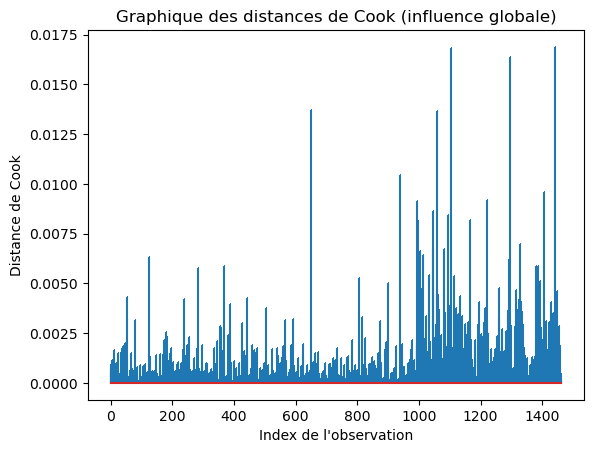

In [9]:
# Test de cook
# Extraction de l'influence à partir du modèle
influence = modele.get_influence()

# Calcul de la distance de Cook pour chaque observation 
cooks, _ = influence.cooks_distance

# Affichage des distances de Cook
print("Distances de Cook :", cooks)

# Visualisation des distances de Cook
plt.stem(np.arange(len(cooks)), cooks, markerfmt=",")
plt.xlabel("Index de l'observation")
plt.ylabel("Distance de Cook")
plt.title("Graphique des distances de Cook (influence globale)")
plt.show()

In [10]:
# Définir cook
cooks, _ = modele.get_influence().cooks_distance

# Nombre total d'observations dans le jeu d'entraînement
n_obs = df_train.shape[0]

# Définir le seuil pour la distance de Cook (4 / n_obs)
seuil = 4 / n_obs
print("Seuil Cook :", seuil)

# Indices des observations dont la distance de Cook est inférieure au seuil
indices_a_conserver = np.where(cooks < seuil)[0]

# Filtrer le DataFrame d'entraînement pour retirer ces observations influentes
df_train_sans_outliers = df_train.iloc[indices_a_conserver]

print("Nombre d'observations initial :", n_obs)
print("Nombre d'observations après retrait :", df_train_sans_outliers.shape[0])

Seuil Cook : 0.002734107997265892
Nombre d'observations initial : 1463
Nombre d'observations après retrait : 1376


In [11]:
# Construction du modèle sans outliers Cook
x_train_cook = df_train_sans_outliers[["diagonal", "height_left", "height_right", "margin_up", "length"]]
y_train_cook = df_train_sans_outliers["margin_low"]

# Ajout d'une constante
x_train_cook_const = sm.add_constant(x_train_cook)

# Création et entraînement du modèle OLS sans outliers Cook
modele_cook = sm.OLS(y_train_cook, x_train_cook_const).fit()

# Affichage du résumé du modèle
print(modele_cook.summary()) 

                            OLS Regression Results                            
Dep. Variable:             margin_low   R-squared:                       0.548
Model:                            OLS   Adj. R-squared:                  0.547
Method:                 Least Squares   F-statistic:                     332.5
Date:                Fri, 01 Aug 2025   Prob (F-statistic):          2.35e-233
Time:                        11:58:50   Log-Likelihood:                -704.29
No. Observations:                1376   AIC:                             1421.
Df Residuals:                    1370   BIC:                             1452.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           25.3604      8.445      3.003   

+ Effectivement, l'augmentation du R² par rapport au modèle incluant les valeurs influentes indique une amélioration de la performance du modèle. Cela signifie que ce dernier explique désormais environ 54,8 % de la variance de la variable margin_low. 
+ Pour la suite du projet, nous allons utiliser le modèle sans les valeurs influentes.
+ Pour une évaluation plus précise du modèle, il est aussi utile de faire une analyse des résidus avec les métriques MAE et RSME

In [12]:
# Calcul des Résidus
residuals = modele_cook.resid

# Calcul du MAE (Mean Absolute Error)
mae = np.mean(np.abs(residuals))
print(f"MAE: {mae}")

# Calcul du RMSE (Root Mean Squared Error)
rmse = np.sqrt(np.mean(residuals ** 2))
print(f"RMSE: {rmse}")

MAE: 0.3249756157692435
RMSE: 0.40369390506119607


+ En moyenne, les prédictions du modèle s’écartent de la réalité d’environ 0.32, ce qui peut être considéré comme une erreur modérée car "margin_low" est comprise entre 3 et 7.
+ Un RMSE inférieur à 1 indique que, généralement, les erreurs de prédiction sont relativement faibles.

In [13]:
# Test Normalité résiduelle
# Appliquer le test de Shapiro-Wilk
stat, p_value = shapiro(residuals)
print(f"Statistique de test: {stat:.5f}, p-value: {p_value:.5f}")

if p_value > 0.05:
    print("Les résidus suivent une distribution normale.")
else:
    print("Les résidus ne suivent pas une distribution normale.")

Statistique de test: 0.99417, p-value: 0.00003
Les résidus ne suivent pas une distribution normale.


In [14]:
# Test de multicolinéarité
# On utilise le DataFrame x_train_const (avec constante ajoutée)
vif_data = pd.DataFrame()
vif_data["feature"] = x_train_cook_const.columns
vif_data["VIF"] = [variance_inflation_factor(x_train_cook_const.values, i) for i in range(x_train_cook_const.shape[1])]

# Affichage des résultats
vif_data

,feature,VIF
0,const,599581.507925
1,diagonal,1.017914
2,height_left,1.127586
3,height_right,1.233111
4,margin_up,1.415804
5,length,1.596671


+ La VIF ou Variance Inflation Factor des variables sont faibles (inférieur à 2) indique qu’il n’y a pas de multicolinéarité problématique entre "margin_low" et ses variables explicatives.

In [15]:
# Test d'homoscédasticité 
# Valeurs prédites du modèle
fitted = modele_cook.fittedvalues

# Application du test de Breusch-Pagan
bp_test = het_breuschpagan(residuals, x_train_cook_const)
labels = ['Lagrange multiplier statistic', 'p-value', 'f-value', 'f p-value']
bp_results = dict(zip(labels, bp_test))

# Affichage des résultats
bp_results

{'Lagrange multiplier statistic': 53.878922236358775,
 'p-value': 2.219411138008128e-10,
 'f-value': 11.16601568574455,
 'f p-value': 1.447236807419974e-10}

+ p-value très faible (p < 0.05) :
On rejette l’hypothèse nulle d’homoscédasticité.
Cela indique qu’il y a une hétéroscédasticité significative dans le modèle
+ f-value et f p-value :
Ces valeurs confirment également la conclusion précédente, avec une p-value très faible, indiquant une violation de l’hypothèse d’homoscédasticité.

Conclusion :
+ Test de normalité des résidus : **non validé**
+ Test de multicolinéarité : **validé**
+ Test d'homoscédastiscité : **non validé**
  
⇒ Malgré les résultats des tests d'homoscédasticité et la normalité des résidus, nous allons néanmoins procéder à l'imputation des valeurs manquantes, car cette méthode est recommandée par notre collègue ayant déjà travaillé avec ces jeux de données et ayant obtenu d'excellents résultats.

In [16]:
# Imputation des valeurs manquantes en utilisant le modèle sans outliers Cook
df_missing = df[df["margin_low"].isna()]
x_missing = df_missing[["diagonal", "height_left", "height_right", "margin_up", "length"]]
x_missing_const = sm.add_constant(x_missing)

# Prédire les valeurs manquantes
predicted_values_no_cook = modele_cook.predict(x_missing_const)

# Imputer les valeurs prédites dans le DataFrame original
df.loc[df["margin_low"].isna(), "margin_low"] = predicted_values_no_cook

print("Imputation terminée en utilisant le modèle sans outliers Cook. Vérifions la colonne 'margin_low'.")

Imputation terminée en utilisant le modèle sans outliers Cook. Vérifions la colonne 'margin_low'.


In [17]:
# Vérification de la colonne "margin_low" après imputation
print(df["margin_low"].isna().sum())  # Doit être 0 si l'imputation a réussi
df["margin_low"].info()

0
<class 'pandas.core.series.Series'>
RangeIndex: 1500 entries, 0 to 1499
Series name: margin_low
Non-Null Count  Dtype  
--------------  -----  
1500 non-null   float64
dtypes: float64(1)
memory usage: 11.8 KB


+ Après imputation, il n'y a plus de valeurs manquantes.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Moteur simple pour classer les billets </h2>
</div>

 Précédemment, nous avons constaté une tendance qui émerge entre les variables "margin_low" et "length" pour distinguer les faux billets : 
  + "margin_low" supérieur à 5
  + "length" inférieur à 112 </br>

Dans cette section, nous allons construire un moteur simple et facilement industrialisable pour classer les faux/vrais billets selon la valeur de "margin_low" et "length"

In [18]:
# Initialisation du dataset
df_moteursimple = df.copy()

# Définition du moteur simple

In [19]:
# Définition de la fonction classifier les faux/vrais billets avec un moteur simple
def moteur_simple_classification(df_moteursimple):
    predictions = []
    
    for _, row in df_moteursimple.iterrows():
        if row['length'] <= 112 and row['margin_low'] >= 5:
            predictions.append(0)  # Faux billet
        else:
            predictions.append(1)  # Vrai billet
    
    return predictions

# Application du moteur simple
df_moteursimple['prediction_simple'] = moteur_simple_classification(df_moteursimple)

# Evaluation du modèle simple

In [20]:
# Évaluation du moteur simple
y_true = df_moteursimple['is_genuine']
y_pred_simple = df_moteursimple['prediction_simple']

# Calcul des métriques
accuracy_simple = accuracy_score(y_true, y_pred_simple)
precision_simple = precision_score(y_true, y_pred_simple)
recall_simple = recall_score(y_true, y_pred_simple)
f1_simple = f1_score(y_true, y_pred_simple)

print(f"Exactitude (Accuracy) : {accuracy_simple:.3f} ({accuracy_simple*100:.1f}%)")
print(f"Précision (Precision) : {precision_simple:.3f} ({precision_simple*100:.1f}%)")
print(f"Rappel (Recall) : {recall_simple:.3f} ({recall_simple*100:.1f}%)")
print(f"F1-Score : {f1_simple:.3f} ({f1_simple*100:.1f}%)")


Exactitude (Accuracy) : 0.827 (82.7%)
Précision (Precision) : 0.794 (79.4%)
Rappel (Recall) : 1.000 (100.0%)
F1-Score : 0.885 (88.5%)


# Matrice de confusion

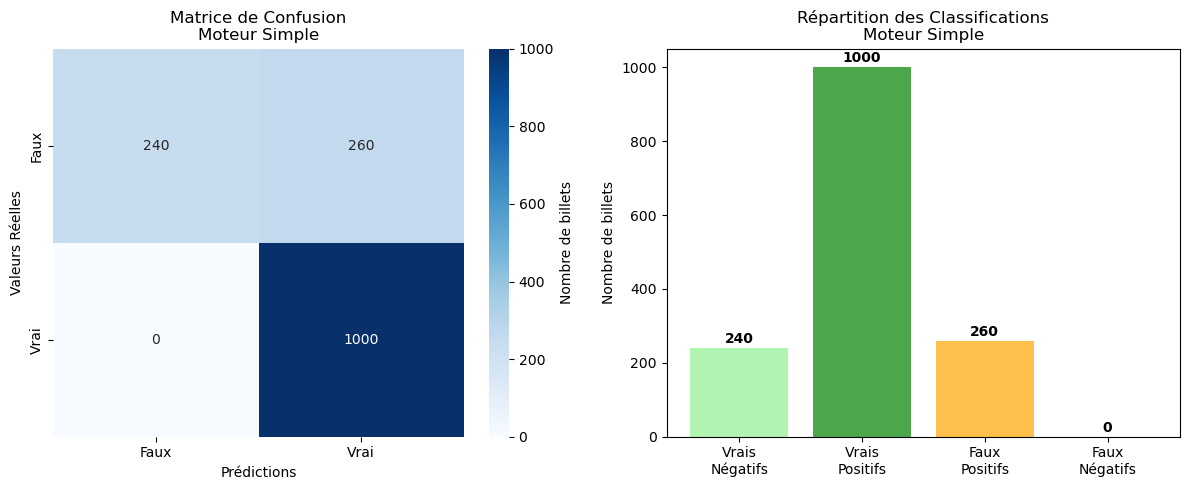

In [21]:
# Matrice de confusion
conf_matrix_simple = confusion_matrix(y_true, y_pred_simple)

plt.figure(figsize=(12, 5))

# Subplot 1: Heatmap de la matrice
plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix_simple, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Faux', 'Vrai'], yticklabels=['Faux', 'Vrai'],
            cbar_kws={'label': 'Nombre de billets'})
plt.title('Matrice de Confusion\nMoteur Simple')
plt.xlabel('Prédictions')
plt.ylabel('Valeurs Réelles')

# Subplot 2: Histogramme des classifications
plt.subplot(1, 2, 2)
# Analyse détaillée des erreurs
tn = conf_matrix_simple[0,0]  # Faux billets correctement identifiés
fp = conf_matrix_simple[0,1]  # Faux billets classés comme vrais
fn = conf_matrix_simple[1,0]  # Vrais billets classés comme faux
tp = conf_matrix_simple[1,1]  # Vrais billets correctement identifiés

# Créer l'histogramme
categories = ['Vrais\nNégatifs', 'Vrais\nPositifs', 'Faux\nPositifs', 'Faux\nNégatifs']
valeurs = [tn, tp, fp, fn]
couleurs = ['lightgreen', 'green', 'orange', 'red']

bars = plt.bar(categories, valeurs, color=couleurs, alpha=0.7)
plt.title('Répartition des Classifications\nMoteur Simple')
plt.ylabel('Nombre de billets')

# Ajouter les valeurs sur les barres
for bar, valeur in zip(bars, valeurs):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 5,
             f'{valeur}', ha='center', va='bottom', fontweight='bold')

# Rotation des labels pour une meilleure lisibilité
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

🌟 Performance globale : environ 80% <br>

💰 Analyse des coûts d'erreur: <br>
   • Billets authentiques rejetés: 0 (perte de confiance) <br>
   • Faux billets acceptés: 260 (perte financière)<br>

**Le modèle entraîne beaucoup de perte financière avec +50% des faux billets non détectés. Il n'est vraiment pas recommandé.**

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Algorithme</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 K-means</h3>
</div>

In [22]:
# Initialisation du dataset
df_kmeans = df.copy()

# Fixer le nombre de cluster optimal

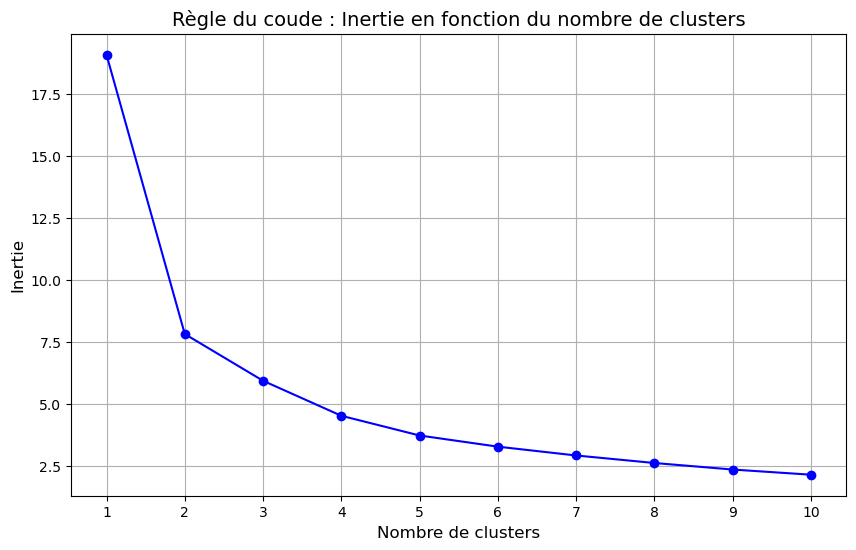

In [23]:
# Règle du coude
# Normalisation des données
scaler = MaxAbsScaler()
kmeans_scaled = scaler.fit_transform(df_kmeans.select_dtypes(include=['float64', 'int64']))

# Calcul de l'inertie pour différents nombres de clusters
inertia = []
cluster_range = range(1, 11)  # Tester de 1 à 10 clusters

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(kmeans_scaled) #scaled
    inertia.append(kmeans.inertia_)

# Tracer la courbe de la règle du coude
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, inertia, marker='o', linestyle='-', color='b')
plt.title("Règle du coude : Inertie en fonction du nombre de clusters", fontsize=14)
plt.xlabel("Nombre de clusters", fontsize=12)
plt.ylabel("Inertie", fontsize=12)
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

+ D'après la courbe ci-dessus, nous allons fixer le nombre de cluster à 2 car c'est là que nous observons un point d'inflexion mais, nous allons le confirmer avec la méthode Silhouette score.

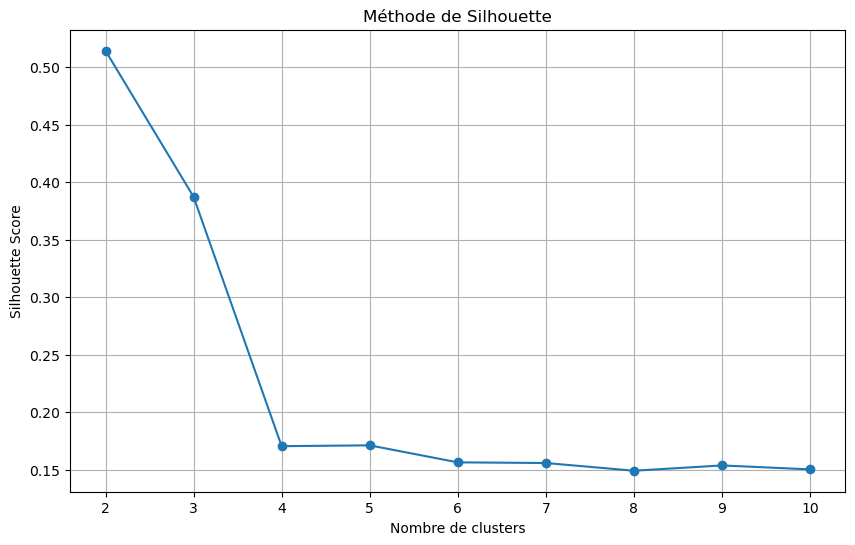

In [24]:
# Sélectionner les colonnes numériques à partir de df_kmeans
numeric_data = df_kmeans.select_dtypes(include=['float64', 'int64'])

# Itérer sur différentes valeurs de k (à partir de 2 car la silhouette nécessite au moins 2 clusters)
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=0)
    labels = kmeans.fit_predict(numeric_data)
    score = silhouette_score(numeric_data, labels)
    silhouette_scores.append(score)

# Visualiser l'évolution du score de silhouette
plt.figure(figsize=(10, 6))
plt.plot(list(k_values), silhouette_scores, marker='o', linestyle='-')
plt.xlabel("Nombre de clusters")
plt.ylabel("Silhouette Score")
plt.title("Méthode de Silhouette")
plt.grid(True)
plt.show()

+ La courbe ci-dessus nous confirme que le nombre de cluster optimal est 2.

# Appliquer le K-means

In [25]:
# Fixer le nombre de clusters 
n= 2
# Appliquer KMeans
kmeans = KMeans(n_clusters=n, random_state=808)
df_kmeans['Cluster'] = kmeans.fit_predict(df_kmeans.select_dtypes(include=['float64', 'int64'])) + 1 

# Caractériser les clusters

+ En analysant les centroïdes de classes

In [26]:
# Centroides des clusters
centers = kmeans.cluster_centers_  
centroids_df = pd.DataFrame(centers, columns=df_kmeans.select_dtypes(include=['float64', 'int64']).columns)

# Définir le nom de chaque cluster
cluster_names = {i: f"Cluster {i+1}" for i in range(centers.shape[0])}
centroids_df['Cluster_Name'] = centroids_df.index.map(cluster_names)

# Réorganiser les colonnes pour mettre le nom du cluster en première colonne
cols = ['Cluster_Name'] + [col for col in centroids_df.columns if col != 'Cluster_Name']
centroids_df = centroids_df[cols]

print("Centroïdes des clusters :")
centroids_df

Centroïdes des clusters :


,Cluster_Name,diagonal,height_left,height_right,margin_low,margin_up,length
0,Cluster 1,171.986844,103.951839,103.813579,4.124181,3.058181,113.195329
1,Cluster 2,171.898634,104.193126,104.145031,5.238600,3.347909,111.590269


+ Caractéristiques des clusters :
  + Cluster 1 : length élevé et margin_low faible;
  + Cluster 2 : length faible et autres variables élevés.
 

+ Avec un radarplot

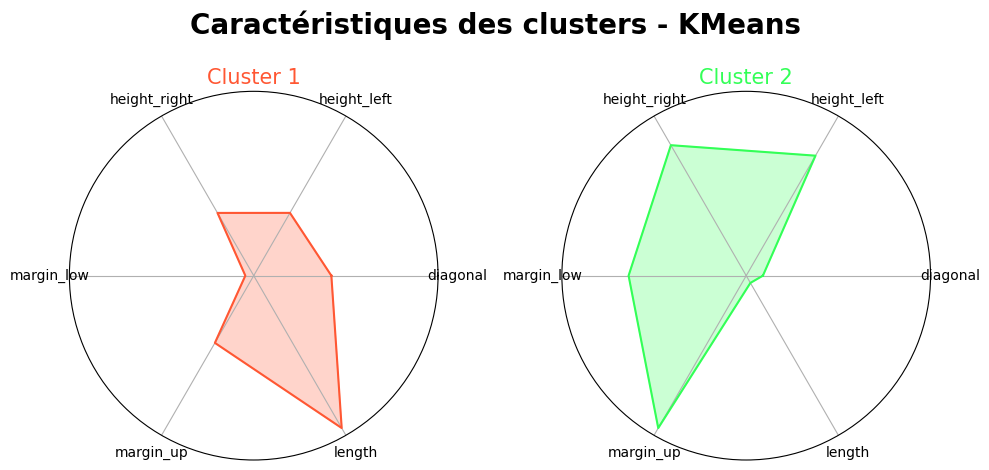

In [27]:
# Normalisation des colonnes numériques
scaler = MinMaxScaler()
numeric_columns = df_kmeans.select_dtypes(include=['float64', 'int64']).columns
df_kmeans[numeric_columns] = scaler.fit_transform(df_kmeans[numeric_columns])

# Préparer les données pour le radar plot
categories = numeric_columns
num_vars = len(categories)
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]

# Définir une liste de couleurs pour les clusters
colors = ['#FF5733', '#33FF57', '#3357FF', '#FF33A1']

# Créer un radar plot pour chaque cluster
fig, axes = plt.subplots(1, 2, figsize=(10, 5), subplot_kw=dict(polar=True))  # Ajuster selon le nombre de clusters
axes = axes.flatten()

for i, cluster_id in enumerate(sorted(df_kmeans['Cluster'].unique())):  # Utiliser df_kmeans['Cluster']
    cluster_data = df_kmeans[df_kmeans['Cluster'] == cluster_id][categories].mean().values  # Moyenne des valeurs par cluster
    cluster_data = np.append(cluster_data, cluster_data[0])  # Boucler les valeurs pour le radar plot
    ax = axes[i]
    ax.fill(angles, cluster_data, alpha=0.25, color=colors[i % len(colors)], label=f'Cluster {cluster_id}')
    ax.plot(angles, cluster_data, color=colors[i % len(colors)], label=f'Cluster {cluster_id}')
    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=10)
    ax.set_title(f'Cluster {cluster_id}', size=15, color=colors[i % len(colors)])

# Ajouter un titre global au graphique
fig.suptitle("Caractéristiques des clusters - KMeans", fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

+ Nous confirmons les caractéristiques des clusters dans l'analyse précédente.

<Figure size 1000x600 with 0 Axes>

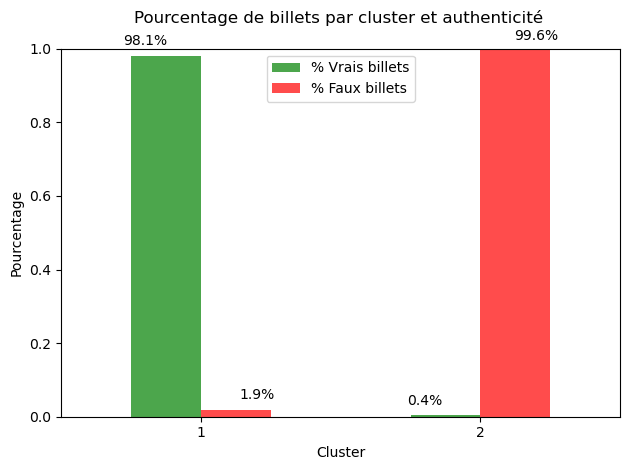

In [28]:
# Répartition des billets par cluster
cluster_analysis = df_kmeans.groupby('Cluster').agg({'is_genuine': ['count', 'sum', 'mean']})
cluster_analysis.columns = ['Total_billets', 'Vrais_billets', 'Pourcentage_vrais']
cluster_analysis['Faux_billets'] = cluster_analysis['Total_billets'] - cluster_analysis['Vrais_billets']
cluster_analysis['Pourcentage_faux'] = 1 - cluster_analysis['Pourcentage_vrais']

# Visualisation des pourcentages de billets par cluster
plt.figure(figsize=(10, 6))

# Graphique: Pourcentages par cluster
ax = cluster_analysis[['Pourcentage_vrais', 'Pourcentage_faux']].plot(kind='bar', color=['green', 'red'], alpha=0.7)
ax.set_title('Pourcentage de billets par cluster et authenticité \n')
ax.set_xlabel('Cluster')
ax.set_ylabel('Pourcentage')
ax.legend(['% Vrais billets', '% Faux billets'], loc='upper center', bbox_to_anchor=(0.5, 1), ncol=1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 1)

# Ajouter des annotations de pourcentage sur le graphique
for i, cluster in enumerate(cluster_analysis.index):
    pct_vrais = cluster_analysis.loc[cluster, 'Pourcentage_vrais']
    pct_faux = cluster_analysis.loc[cluster, 'Pourcentage_faux']
    ax.text(i-0.2, pct_vrais + 0.02, f'{pct_vrais:.1%}', ha='center', va='bottom')
    ax.text(i+0.2, pct_faux + 0.02, f'{pct_faux:.1%}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

+ Le clusters 1 correspond majoritairement aux vrais billets billets (98.1%).
+ Le cluster 2 correspond majoritairement aux faux billets (99.6%).
+ Nous pouvons donc dire que les vrais billets ont la caractéristique du cluster 1, c'est-à-dire length élevé et margin_low faible.

# Evaluation du modèle K-Means

In [29]:
# Créer les prédictions basées sur les clusters
# D'après notre analyse: Cluster 1 → Vrai billet, Cluster 2 → Faux billet
def cluster_to_prediction(cluster):
    if cluster == 1:
        return 1  # Vrai billet
    else:  # cluster == 2
        return 0  # Faux billet

# Appliquer la fonction de mapping
df_kmeans['Prediction_kmeans'] = df_kmeans['Cluster'].apply(cluster_to_prediction)

# Calculer les métriques de performance
y_true = df_kmeans['is_genuine']
y_pred = df_kmeans['Prediction_kmeans']

# 1. Accuracy (Exactitude)
accuracy = accuracy_score(y_true, y_pred)
print(f"Exactitude (Accuracy) : {accuracy:.3f} ({accuracy*100:.1f}%)")

# 2. Precision (Précision)
precision = precision_score(y_true, y_pred)
print(f"Précision (Precision) : {precision:.3f} ({precision*100:.1f}%)")

# 3. Recall (Rappel/Sensibilité) (problematique fonctionnelle)
recall = recall_score(y_true, y_pred)
print(f"Rappel (Recall) : {recall:.3f} ({recall*100:.1f}%)")

# 4. F1-Score
f1 = f1_score(y_true, y_pred)
print(f"F1-Score : {f1:.3f} ({f1*100:.1f}%)")   



Exactitude (Accuracy) : 0.986 (98.6%)
Précision (Precision) : 0.981 (98.1%)
Rappel (Recall) : 0.998 (99.8%)
F1-Score : 0.990 (99.0%)


+ Matrice de confusion

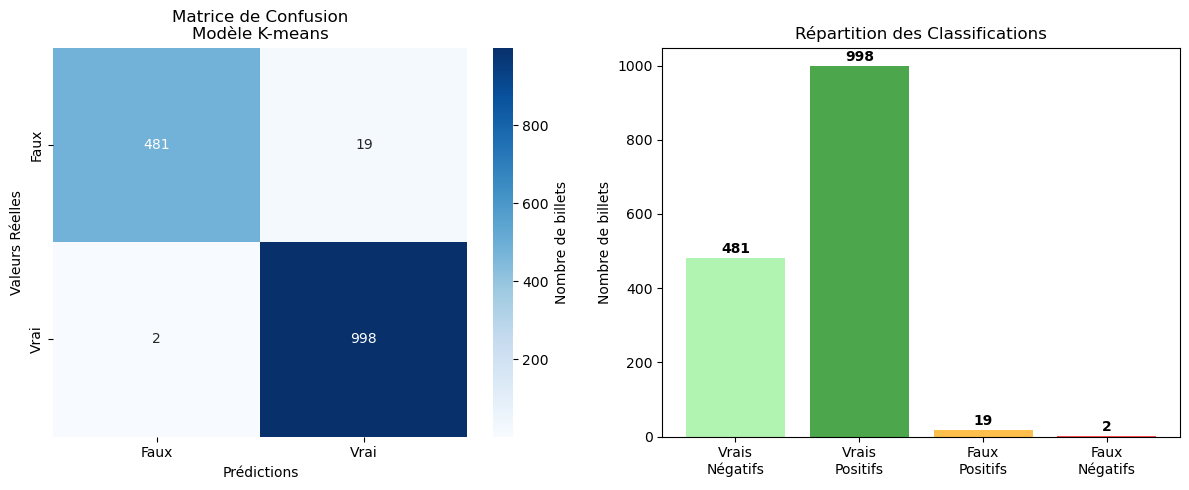

In [30]:
# Calculer la matrice de confusion
conf_matrix = confusion_matrix(y_true, y_pred)

# Extraire les composants de la matrice
vrais_negatifs = conf_matrix[0,0]  # TN - Faux billets correctement identifiés
faux_positifs = conf_matrix[0,1]   # FP - Faux billets classés comme vrais  
faux_negatifs = conf_matrix[1,0]   # FN - Vrais billets classés comme faux
vrais_positifs = conf_matrix[1,1]  # TP - Vrais billets correctement identifiés

# Visualisation de la matrice de confusion
plt.figure(figsize=(12, 5))

# Subplot 1: Heatmap de la matrice
plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Faux', 'Vrai'], yticklabels=['Faux', 'Vrai'],
            cbar_kws={'label': 'Nombre de billets'})
plt.title('Matrice de Confusion\nModèle K-means')
plt.xlabel('Prédictions')
plt.ylabel('Valeurs Réelles')

# Subplot 2: Graphique en barres des erreurs
plt.subplot(1, 2, 2)
categories = ['Vrais\nNégatifs', 'Vrais\nPositifs', 'Faux\nPositifs', 'Faux\nNégatifs']
valeurs = [vrais_negatifs, vrais_positifs, faux_positifs, faux_negatifs]
couleurs = ['lightgreen', 'green', 'orange', 'red']

bars = plt.bar(categories, valeurs, color=couleurs, alpha=0.7)
plt.title('Répartition des Classifications')
plt.ylabel('Nombre de billets')

# Ajouter les valeurs sur les barres
for bar, valeur in zip(bars, valeurs):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 5,
             f'{valeur}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

🌟 Performance globale: Excellente (98%) <br>

💰 Analyse des coûts d'erreur: <br>
   • Billets authentiques rejetés: 2 (perte de confiance) <br>
   • Faux billets acceptés: 19 (perte financière)<br>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 Régression logistique</h3>
</div>

In [31]:
# Initialisation du dataset
df_rl = df.copy()

# Diviser les données en ensemble d'entraînement et de test

In [32]:
# Sélectionner les variables explicatives et la variable cible
X = df_rl[['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']]
y = df_rl['is_genuine']

# Division des données en ensemble d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Taille de l'ensemble d'entraînement: {X_train.shape[0]}")
print(f"\nTaille de l'ensemble de test: {X_test.shape[0]}")
print(f"\nRépartition dans l'ensemble d'entraînement:")
print(y_train.value_counts())
print(f"\nRépartition dans l'ensemble de test:")
print(y_test.value_counts())

Taille de l'ensemble d'entraînement: 1200

Taille de l'ensemble de test: 300

Répartition dans l'ensemble d'entraînement:
is_genuine
True     800
False    400
Name: count, dtype: int64

Répartition dans l'ensemble de test:
is_genuine
True     200
False    100
Name: count, dtype: int64


# Appliquer le modèle de régression logistique

In [33]:
# Création et entraînement du modèle de régression logistique
# Normalisation des données
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
log_reg = LogisticRegression(random_state=808).fit(X_train_scaled, y_train)

# Prédictions sur l'ensemble de test
y_pred = log_reg.predict(X_test_scaled)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Modèle de régression logistique entraîné avec succès!")
print(f"Score d'entraînement: {log_reg.score(X_train_scaled, y_train):.3f}")
print(f"Score de test: {log_reg.score(X_test_scaled, y_test):.3f}")

Modèle de régression logistique entraîné avec succès!
Score d'entraînement: 0.993
Score de test: 0.990


<Axes: ylabel='Count'>

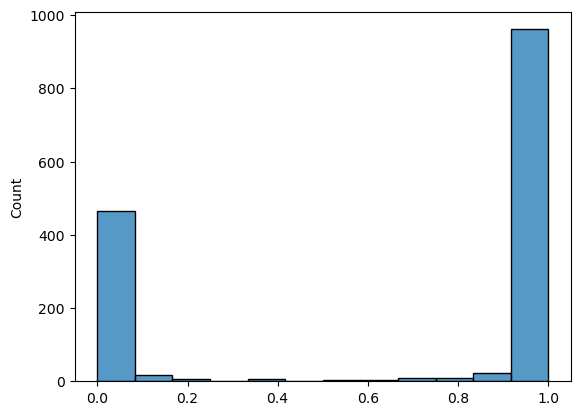

In [34]:
# Histogramme des probabilités prédites
X_scaled = scaler.transform(X)
y_hat_proba = log_reg.predict_proba(X_scaled)[:,1]
import seaborn as sns
sns.histplot(y_hat_proba)

+ Le modèle est assez fiable au niveau de ses prédictions, la plupart des prédictions ont une probabilité proche de 0 ou de 1.

# Evaluer le modèle de régression logistique

In [35]:
# Calcul des métriques de performance pour la régression logistique
# 1. Accuracy (Exactitude)
accuracy = accuracy_score(y_test, y_pred)
print(f"Exactitude (Accuracy) : {accuracy:.3f} ({accuracy*100:.1f}%)")

# 2. Precision (Précision)
precision = precision_score(y_test, y_pred)
print(f"Précision (Precision) : {precision:.3f} ({precision*100:.1f}%)")

# 3. Recall (Rappel/Sensibilité) (problematique fonctionnelle)
recall = recall_score(y_test, y_pred)
print(f"Rappel (Recall) : {recall:.3f} ({recall*100:.1f}%)")

# 4. F1-Score
f1 = f1_score(y_test, y_pred)
print(f"F1-Score : {f1:.3f} ({f1*100:.1f}%)")   

Exactitude (Accuracy) : 0.990 (99.0%)
Précision (Precision) : 0.990 (99.0%)
Rappel (Recall) : 0.995 (99.5%)
F1-Score : 0.993 (99.3%)


+ L'ensemble des métriques atteint 99 %, ce qui indique une excellente performance du modèle de régression logistique.

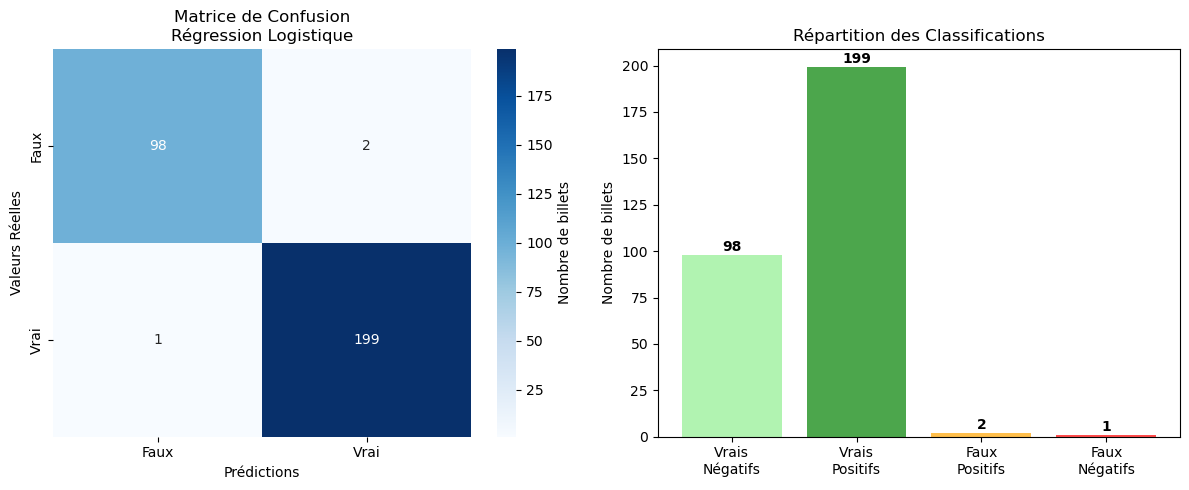

In [36]:
# Matrice de confusion pour la régression logistique
conf_matrix_lr = confusion_matrix(y_test, y_pred)

# Extraire les composants de la matrice
tn_lr = conf_matrix_lr[0,0]  # TN - Faux billets correctement identifiés
fp_lr = conf_matrix_lr[0,1]  # FP - Faux billets classés comme vrais  
fn_lr = conf_matrix_lr[1,0]  # FN - Vrais billets classés comme faux
tp_lr = conf_matrix_lr[1,1]  # TP - Vrais billets correctement identifiés

# Visualisation de la matrice de confusion
plt.figure(figsize=(12, 5))

# Subplot 1: Heatmap de la matrice
plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix_lr, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Faux', 'Vrai'], yticklabels=['Faux', 'Vrai'],
            cbar_kws={'label': 'Nombre de billets'})
plt.title('Matrice de Confusion\nRégression Logistique')
plt.xlabel('Prédictions')
plt.ylabel('Valeurs Réelles')

# Subplot 2: Graphique en barres des erreurs
plt.subplot(1, 2, 2)
categories = ['Vrais\nNégatifs', 'Vrais\nPositifs', 'Faux\nPositifs', 'Faux\nNégatifs']
valeurs = [tn_lr, tp_lr, fp_lr, fn_lr]
couleurs = ['lightgreen', 'green', 'orange', 'red']

bars = plt.bar(categories, valeurs, color=couleurs, alpha=0.7)
plt.title('Répartition des Classifications')
plt.ylabel('Nombre de billets')

# Ajouter les valeurs sur les barres
for bar, valeur in zip(bars, valeurs):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.5,
             f'{valeur}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

🌟 Performance globale: Excellente (99%) <br>

💰 Analyse des coûts d'erreur: <br>
   • Billets authentiques rejetés: 1 (perte de confiance) <br>
   • Faux billets acceptés: 2 (perte financière)<br>

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Conclusion</h2>
</div>

Le modèle de régression logistique, avec un score de 99 %, est plus performant pour la détection de faux billets que le modèle K-means, qui affiche un score de 98 %. De plus, la régression logistique est un modèle équilibré, ce qui limite le risque de pertes financières importantes pour les faux billets acceptés. Nous allons donc comparer leurs courbes ROC pour confirmer cette performance.

# Comparaison des courbes ROC des deux modèles

+ Calcul des courbes ROC

In [37]:
# 1. Régression logistique 
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba)
auc_lr = auc(fpr_lr, tpr_lr)

# 2. K-means 
X_test_kmeans = X_test_scaled.copy()

# Calcul des distances aux centroïdes pour chaque point de test
distances = kmeans.transform(X_test_kmeans)

# Conversion des distances en probabilités 
# Distance au centroïde 0 (vrais billets) et centroïde 1 (faux billets)
dist_vrai = distances[:, 0]  # Distance au cluster des vrais billets (Cluster 1)
dist_faux = distances[:, 1]  # Distance au cluster des faux billets (Cluster 2)

# Calcul de la probabilité d'être un VRAI billet basée sur les distances relatives
# Plus on est proche du centroïde des vrais billets, plus la probabilité d'être vrai est élevée
total_distances = dist_vrai + dist_faux
prob_vrai_kmeans = dist_faux / total_distances  # Plus on est loin des faux, plus on est vrai

# Courbe ROC pour K-means (on utilise la probabilité d'être un vrai billet)
fpr_kmeans, tpr_kmeans, _ = roc_curve(y_test, prob_vrai_kmeans)
auc_kmeans = auc(fpr_kmeans, tpr_kmeans)

In [38]:
# Affichage des scores AUC
print(f"AUC Régression logistique : {auc_lr:.4f}")
print(f"AUC K-means : {auc_kmeans:.4f}")

AUC Régression logistique : 0.9995
AUC K-means : 0.9975


# Visualisation des courbes ROC

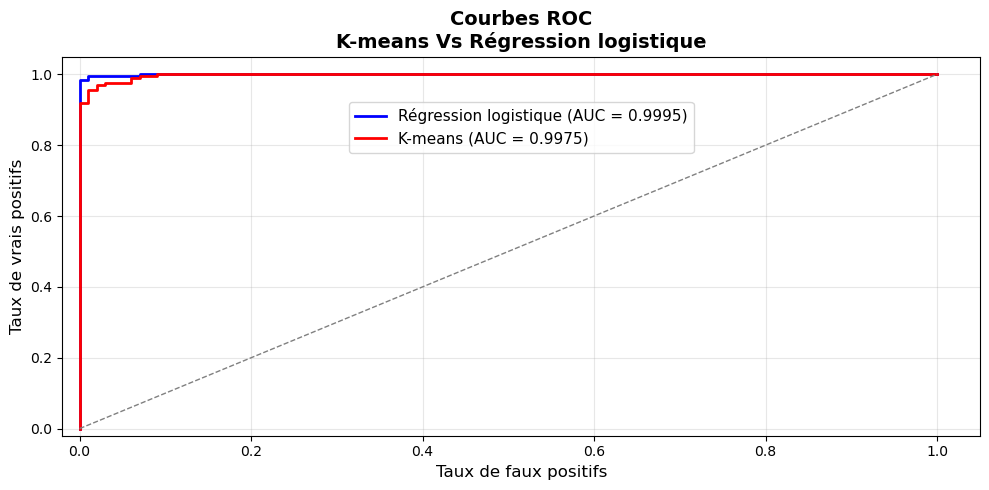

In [39]:
# Graphique comparatif des courbes ROC
plt.figure(figsize=(10, 5))

# Courbe ROC - Régression logistique
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, 
         label=f'Régression logistique (AUC = {auc_lr:.4f})')

# Courbe ROC - K-means
plt.plot(fpr_kmeans, tpr_kmeans, color='red', lw=2, 
         label=f'K-means (AUC = {auc_kmeans:.4f})')

# Ligne de référence (classificateur aléatoire)
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')

# Mise en forme du graphique
plt.xlim([-0.02, 1.05])
plt.ylim([-0.02, 1.05])
plt.xlabel('Taux de faux positifs', fontsize=12)
plt.ylabel('Taux de vrais positifs', fontsize=12)
plt.title('Courbes ROC\nK-means Vs Régression logistique', fontsize=14, fontweight='bold')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 0.9), ncol=1, fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


D'après les courbes ci-dessus, nous retenons le modèle de régression logistique pour la mise en production, car c'est celui dont la courbe ROC est plus proche de la réalité.

# Exporter le modèle de régression logistique

In [ ]:
# Exporter le modèle de régression logistique 
nom_fichier_modele = "modele_regression_logistique_faux_billets.pkl"
chemin_modele= os.path.join(chemin, "Livrables", nom_fichier_modele)

# Exporter le modèle entraîné
with open(chemin_modele, 'wb') as fichier:
    pickle.dump(log_reg, fichier)

print(f"✅ Modèle exporté avec succès !")
print(f"📁 Modèle : {chemin_modele}")
print(f"📊 Type de modèle : {type(log_reg).__name__}")
print(f"🎯 Performance sur test : {log_reg.score(X_test_scaled, y_test):.3f}")

# Informations supplémentaires sur le modèle
print(f"\n📋 Informations du modèle :")
print(f"   • Variables d'entrée : {list(X.columns)}")
print(f"   • Random state : {log_reg.random_state}")
print(f"   • Standardisation des données : StandardScaler")

✅ Modèle exporté avec succès !
📁 Modèle : C:\Users\CRFP4534\OneDrive - orange.com\Bureau\Formation CFA - Data Analyst\P10-Détectez des faux billets avec R ou Python\\Livrables\modele_regression_logistique_faux_billets.pkl
📊 Type de modèle : LogisticRegression
🎯 Performance sur test : 0.990

📋 Informations du modèle :
   • Variables d'entrée : ['diagonal', 'height_left', 'height_right', 'margin_low', 'margin_up', 'length']
   • Random state : 808
   • Standardisation des données : StandardScaler
